In [ ]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

plt.rcParams["figure.figsize"] = (12, 5)
pd.options.display.float_format = "{:.2f}".format

In [ ]:
TICKERS = {
    "SPY": "Actions US",        "QQQ": "Nasdaq 100",        "IWM": "Small caps US",
    "EFA": "Actions dév. hors US", "EEM": "Actions émergentes",
    "TLT": "Treasuries 20 ans+", "IEF": "Treasuries 7-10 ans", "SHY": "Treasuries 1-3 ans",
    "LQD": "Crédit Investment Grade", "TIP": "Obligations indexées inflation",
    "GLD": "Or", "DBC": "Matières premières", "VNQ": "Immobilier coté (REIT)",
}
START = "2006-03-01"
LOOKBACK = 252
COST_BPS = 10
MAX_WEIGHT = 0.40

## Données + Prix ajustés (dividendes inclus) de 13 ETF multi-actifs, téléchargés depuis Yahoo Finance.

5199 jours, du 2006-03-02 au 2026-10-29


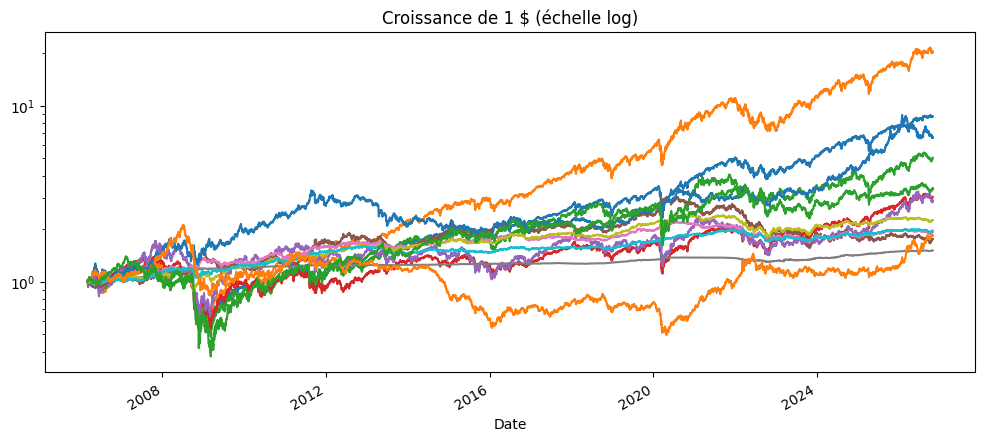

In [ ]:
raw = yf.download(list(TICKERS), start=START, auto_adjust=True, progress=False)
prices = raw["Close"][list(TICKERS)].dropna()
returns = prices.pct_change().dropna()

print(f"{len(returns)} jours, du {returns.index[0].date()} au {returns.index[-1].date()}")
(prices / prices.iloc[0]).plot(logy=True, title="Croissance de 1 $ (échelle log)", legend=False)
plt.show()

## Les 5 méthodes d'allocation + Équipondéré, Max Sharpe, Variance minimale, Risk Parity et HRP. La covariance est estimée avec Ledoit-Wolf.

In [ ]:
def estimate(window):
    mu = window.mean().values * 252
    cov = LedoitWolf().fit(window.values).covariance_ * 252
    return mu, cov

def _optimize(objective, n, max_w=MAX_WEIGHT):
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    res = minimize(objective, np.ones(n) / n, method="SLSQP",
                   bounds=[(0, max_w)] * n, constraints=cons)
    w = np.clip(res.x, 0, None)
    return w / w.sum()

def equal_weight(window):
    n = window.shape[1]
    return np.ones(n) / n

def max_sharpe(window):
    mu, cov = estimate(window)
    return _optimize(lambda w: -(w @ mu) / np.sqrt(w @ cov @ w), len(mu))

def min_variance(window):
    _, cov = estimate(window)
    return _optimize(lambda w: w @ cov @ w, cov.shape[0])

def risk_parity(window):
    _, cov = estimate(window)
    n = cov.shape[0]
    obj = lambda w: 0.5 * w @ cov @ w - np.log(w).sum() / n
    grad = lambda w: cov @ w - 1 / (n * w)
    res = minimize(obj, np.ones(n) / n, jac=grad, method="L-BFGS-B", bounds=[(1e-8, None)] * n)
    return res.x / res.x.sum()

def _cluster_var(cov, idx):
    sub = cov[np.ix_(idx, idx)]
    ivp = 1 / np.diag(sub)
    ivp /= ivp.sum()
    return ivp @ sub @ ivp

def hrp_order(cov):
    std = np.sqrt(np.diag(cov))
    corr = np.clip(cov / np.outer(std, std), -1, 1)
    dist = np.sqrt(0.5 * (1 - corr))
    np.fill_diagonal(dist, 0)
    link = linkage(squareform(dist, checks=False), method="single")
    return link, list(leaves_list(link))

def hrp(window):
    _, cov = estimate(window)
    _, order = hrp_order(cov)
    w = pd.Series(1.0, index=order)
    clusters = [order]
    while clusters:
        clusters = [c[a:b] for c in clusters if len(c) > 1
                    for a, b in ((0, len(c) // 2), (len(c) // 2, len(c)))]
        for i in range(0, len(clusters), 2):
            c1, c2 = clusters[i], clusters[i + 1]
            v1, v2 = _cluster_var(cov, c1), _cluster_var(cov, c2)
            alpha = 1 - v1 / (v1 + v2)
            w.loc[c1] *= alpha
            w.loc[c2] *= 1 - alpha
    return w.sort_index().values

METHODS = {
    "Équipondéré": equal_weight,
    "Max Sharpe": max_sharpe,
    "Variance min": min_variance,
    "Risk Parity": risk_parity,
    "HRP": hrp,
}

## Backtest + Chaque mois, les poids sont recalculés avec uniquement les 12 derniers mois de données. 10 pb de frais par transaction.

In [ ]:
def backtest(returns, weight_fn, lookback=LOOKBACK, cost_bps=COST_BPS):
    R = returns.values
    dates = returns.index
    month_end = returns.groupby(returns.index.to_period("M")).tail(1).index
    is_rebal = dates.isin(month_end)
    start = lookback - 1
    while not is_rebal[start]:
        start += 1

    w = None
    pnl, w_hist, to_hist = {}, {}, {}
    for i in range(start, len(dates)):
        if w is not None:
            gross = w @ R[i]
            pnl[dates[i]] = gross
            w = w * (1 + R[i]) / (1 + gross)
        if is_rebal[i]:
            target = weight_fn(returns.iloc[i - lookback + 1 : i + 1])
            turnover = np.abs(target - (w if w is not None else 0)).sum()
            if w is not None:
                pnl[dates[i]] -= turnover * cost_bps / 1e4
            w = target
            w_hist[dates[i]] = target
            to_hist[dates[i]] = turnover
    weights = pd.DataFrame(w_hist, index=returns.columns).T
    return pd.Series(pnl), weights, pd.Series(to_hist)

results = {name: backtest(returns, fn) for name, fn in METHODS.items()}
port = pd.DataFrame({k: v[0] for k, v in results.items()}).dropna()
weights = {k: v[1] for k, v in results.items()}
turnover = {k: v[2] for k, v in results.items()}
print("Backtest terminé")

Backtest terminé


In [ ]:
def max_drawdown(r):
    wealth = (1 + r).cumprod()
    return (wealth / wealth.cummax() - 1).min()

def stats(r, name):
    years = len(r) / 252
    cagr = (1 + r).prod() ** (1 / years) - 1
    vol = r.std() * np.sqrt(252)
    mdd = max_drawdown(r)
    w = weights[name]
    return {
        "Rendement annuel %": 100 * cagr,
        "Volatilité %": 100 * vol,
        "Sharpe": (r.mean() * 252) / vol,
        "Max drawdown %": 100 * mdd,
        "Calmar": cagr / abs(mdd),
        "Turnover annuel %": 100 * turnover[name].iloc[1:].mean() * 12,
        "Nb effectif d'actifs": (1 / (w ** 2).sum(axis=1)).mean(),
    }

summary = pd.DataFrame({k: stats(port[k], k) for k in port}).T
summary.sort_values("Sharpe", ascending=False)

,Rendement annuel %,Volatilité %,Sharpe,Max drawdown %,Calmar,Turnover annuel %,Nb effectif d'actifs
HRP,2.84,2.86,0.99,-9.60,0.30,98.10,2.39
Risk Parity,4.31,5.22,0.83,-15.66,0.28,43.19,6.50
Variance min,3.04,3.67,0.83,-12.70,0.24,73.92,3.89
Max Sharpe,5.67,7.27,0.80,-17.73,0.32,443.38,3.73
Équipondéré,6.61,10.76,0.65,-33.32,0.20,31.76,13.00


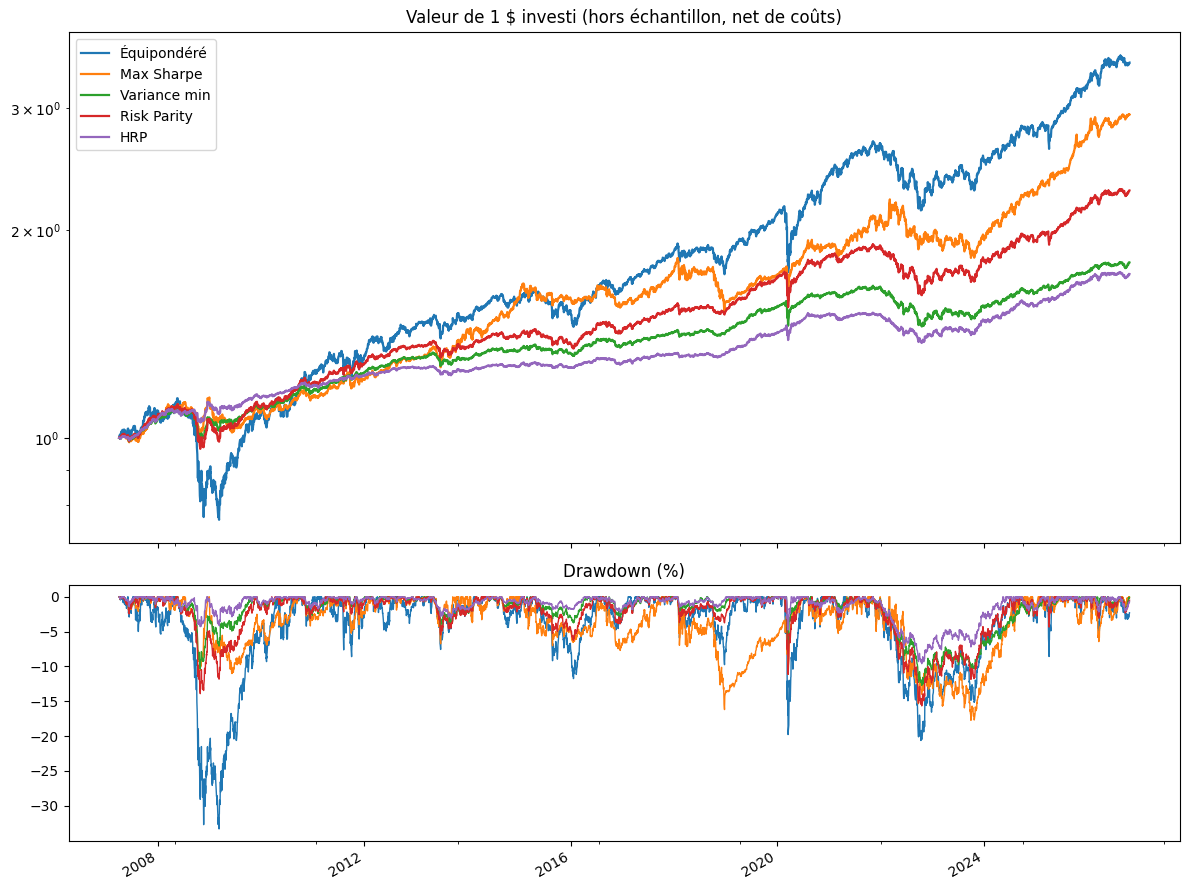

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
wealth = (1 + port).cumprod()
wealth.plot(ax=ax1, logy=True, lw=1.6)
ax1.set_title("Valeur de 1 $ investi (hors échantillon, net de coûts)")
(wealth / wealth.cummax() - 1).mul(100).plot(ax=ax2, lw=1, legend=False)
ax2.set_title("Drawdown (%)")
plt.tight_layout()
plt.show()

## Stress tests + Performance pendant la crise de 2008, le Covid et la hausse des taux de 2022.

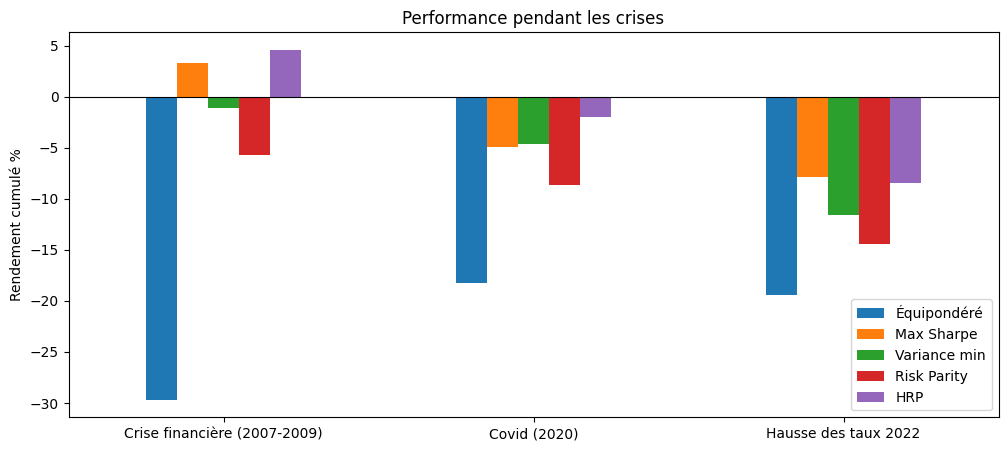

,Équipondéré,Max Sharpe,Variance min,Risk Parity,HRP
Crise financière (2007-2009),-29.69,3.34,-1.11,-5.68,4.59
Covid (2020),-18.21,-4.97,-4.66,-8.65,-1.99
Hausse des taux 2022,-19.44,-7.86,-11.56,-14.44,-8.50


In [ ]:
CRISES = {
    "Crise financière (2007-2009)": ("2007-10-09", "2009-03-09"),
    "Covid (2020)": ("2020-02-19", "2020-03-23"),
    "Hausse des taux 2022": ("2022-01-03", "2022-10-12"),
}
stress = pd.DataFrame({
    crisis: ((1 + port.loc[a:b]).prod() - 1) * 100
    for crisis, (a, b) in CRISES.items()
    if len(port.loc[a:b]) > 0
}).T
stress.plot.bar(figsize=(12, 5), rot=0)
plt.ylabel("Rendement cumulé %")
plt.title("Performance pendant les crises")
plt.axhline(0, color="black", lw=0.8)
plt.show()
stress

## Robustesse
Le Sharpe recalculé avec 0, 10, 25 et 50 pb de frais, pour vérifier que le classement tient.

In [ ]:
sens = {}
for c in [0, 10, 25, 50]:
    row = {}
    for name, fn in METHODS.items():
        r, _, _ = backtest(returns, fn, cost_bps=c)
        row[name] = (r.mean() * 252) / (r.std() * np.sqrt(252))
    sens[f"{c} pb"] = row
print("Ratio de Sharpe selon les coûts de transaction")
pd.DataFrame(sens)

Ratio de Sharpe selon les coûts de transaction


,0 pb,10 pb,25 pb,50 pb
Équipondéré,0.65,0.65,0.64,0.64
Max Sharpe,0.86,0.80,0.70,0.55
Variance min,0.85,0.83,0.80,0.75
Risk Parity,0.84,0.83,0.82,0.80
HRP,1.02,0.99,0.94,0.85



La volatilité est indiquée par la hauteur et la couleur. La couleur est plafonnée à 60 % afin d’assurer une bonne lisibilité : les pics qui dépassent cette valeur apparaissent en rouge foncé, mais la hauteur représente toujours la valeur réelle de la volatilité.

In [31]:
import plotly.graph_objects as go

TICKER = "SPY"
THEME = "plotly_white"   # remplace par "plotly_dark" pour un fond noir

# Données : prix du SPY et rendements journaliers
px = yf.download(TICKER, start="2015-01-01", auto_adjust=True, progress=False)["Close"].squeeze()
r = np.log(px).diff().dropna()

# Volatilité réalisée annualisée sur plusieurs fenêtres (en jours de bourse)
WINDOWS = {"1S": 5, "2S": 10, "1M": 21, "2M": 42, "3M": 63, "4M": 84, "6M": 126, "9M": 189, "1A": 252}
vol_all = pd.DataFrame({k: r.rolling(n).std() * np.sqrt(252) * 100 for k, n in WINDOWS.items()}).dropna()
vol = vol_all.iloc[-504:]
cur = vol_all.iloc[-1]
pct = (vol_all <= cur).mean() * 100

# Textes du titre
titre = "Surface de volatilité réalisée : " + TICKER
sous_titre = "Volatilité 1 mois actuelle : " + str(round(cur["1M"], 1)) + " % (percentile " + str(round(pct["1M"])) + ")"

# Surface 3D
fig = go.Figure(go.Surface(z=vol.values.T, x=vol.index, y=list(WINDOWS.values()),
                           colorscale="Turbo", cmin=vol.values.min(), cmax=60,
                           colorbar=dict(title="Vol %")))
fig.update_layout(template=THEME, height=700, margin=dict(l=0, r=0, t=90, b=0),
                  title=dict(text=titre + "<br><sup>" + sous_titre + "</sup>"))
fig.update_scenes(xaxis_title="Date", zaxis_title="Vol annualisée %",
                  yaxis=dict(title="Fenêtre", tickvals=list(WINDOWS.values()), ticktext=list(WINDOWS)),
                  camera=dict(eye=dict(x=1.6, y=-1.6, z=0.8)))
fig.show()

In [ ]:
x = list(WINDOWS)
lignes = [("Max", vol_all.max(), "dot"),
          ("75e percentile", vol_all.quantile(0.75), "dash"),
          ("Médiane", vol_all.median(), "solid"),
          ("25e percentile", vol_all.quantile(0.25), "dash"),
          ("Min", vol_all.min(), "dot")]

fig2 = go.Figure()
for label, s, dash in lignes:
    fig2.add_trace(go.Scatter(x=x, y=s, name=label, line=dict(color="#9ca3af", dash=dash, width=1.5)))
fig2.add_trace(go.Scatter(x=x, y=cur, name="Actuelle", mode="lines+markers",
                          line=dict(color="#d97706", width=3), marker=dict(size=8)))

titre2 = "Cône de volatilité : " + TICKER
sous_titre2 = "Ligne orange : niveau actuel. Lignes grises : historique depuis " + str(vol_all.index[0].year)
fig2.update_layout(template=THEME, height=500, xaxis_title="Fenêtre", yaxis_title="Vol annualisée %",
                   title=dict(text=titre2 + "<br><sup>" + sous_titre2 + "</sup>"))
fig2.show()

In [ ]:
weights["HRP"].mean().sort_values(ascending=False).round(2)

,0
Ticker,
SHY,0.64
TIP,0.10
IEF,0.08
LQD,0.07
GLD,0.02
TLT,0.02
DBC,0.02
VNQ,0.01
SPY,0.01


## Conclusions

**Meilleur Sharpe : le HRP.** Il obtient 0,99 avec 10 pb de frais et reste premier jusqu'à 50 pb (0,85). C'est le résultat le plus stable face aux coûts.

**Mais une nuance importante.** Le HRP est en réalité un portefeuille très prudent : il place en moyenne 64 % sur les obligations courtes (SHY) et environ 91 % sur l'ensemble des obligations, contre environ 5 % sur les actions. Son nombre effectif d'actifs n'est que de 2,39 sur 13. Sa faible volatilité (2,86 %) et sa bonne tenue en crise viennent surtout de là. De plus, le Sharpe est calculé avec un taux sans risque nul : le rendement des obligations courtes, proche de celui du cash, est donc compté comme une performance, ce qui avantage le HRP.

**Markowitz.** Le Max Sharpe est deuxième sans frais (0,86), mais son turnover de 443 % par an le fait chuter à 0,55 avec 50 pb. Ses poids changent beaucoup d'un mois à l'autre, ce qui le rend très sensible aux coûts.

**Équipondéré.** Il a le rendement le plus élevé (6,61 % par an), mais aussi la volatilité la plus forte (10,76 %) et la pire chute (-33 %). C'est la méthode la plus touchée dans les trois crises : -29,69 % en 2008, -18,21 % en 2020, -19,44 % en 2022.

**Crises.** Le HRP se démarque en 2008 (+ 4,59 %) et au cours de la crise Covid (- 1,99 %). Sa forte allocation aux obligations courtes lui permet de limiter les pertes. En 2022, tous les portefeuilles ont baissé en raison de la chute simultanée des actions et des obligations.

**Limites**

- Analyse portant sur une seule période historique incluant trois crises.

- Biais de sélection des 13 ETF choisis aujourd'hui.

- Taux sans risque considéré nul, favorisant les portefeuilles obligataires.

- Les résultats passés ne garantissent pas les performances futures.